#1. Memanggil Library

In [ ]:
import pandas as pd
import pandas_gbq
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

#2. Koneksi ke Big Query

In [ ]:
from google.colab import auth
auth.authenticate_user()
print("Login berhasil!")

Login berhasil!


In [ ]:
from google.cloud import bigquery

PROJECT_ID = "searadata-513813"   # GANTI dengan Project ID kalian, tetap di dalam tanda kutip

client = bigquery.Client(project=PROJECT_ID)
print("Terhubung ke project:", PROJECT_ID)

Terhubung ke project: searadata-513813


#3. Menampilkan Seluruh Data di Database SakuNusa

In [ ]:
sakunusa = f"""
SELECT
t.txn_id,
t.txn_datetime,
t.txn_type,
t.amount,
t.cashback_amount,
t.status,
u.user_id,
u.signup_date,
u.city,
u.gender,
u.birth_year,
u.acquisition_channel,
u.kyc_status,
m.merchant_id,
m.category,
m.city,
m.join_date,
m.merchant_name,
p.promo_id,
p.promo_name,
p.target,
p.start_date,
p.end_date,
p.cashback_persen,
p.maks_cashback,
p.min_transaksi
FROM `searadata-513813.sakunusa.transactions` AS t
LEFT JOIN `searadata-513813.sakunusa.users` AS u
  ON t.user_id = u.user_id
LEFT JOIN `searadata-513813.sakunusa.merchants` AS m
  ON t.merchant_id = m.merchant_id
LEFT JOIN `searadata-513813.sakunusa.promos` AS p
  ON t.promo_id = p.promo_id
"""

df_sakunusa = client.query(sakunusa).to_dataframe()
df_sakunusa

,txn_id,txn_datetime,txn_type,amount,cashback_amount,status,user_id,signup_date,city,gender,...,join_date,merchant_name,promo_id,promo_name,target,start_date,end_date,cashback_persen,maks_cashback,min_transaksi
0,TX000412,2026-07-02 08:39:00+00:00,Transfer,25000,0,Berhasil,U01223,2026-04-28,Jakarta,Perempuan,...,NaT,None,None,None,None,NaT,NaT,<NA>,<NA>,<NA>
1,TX006869,2026-07-18 19:30:57+00:00,Transfer,25000,0,Gagal,U00648,2026-03-08,Yogyakarta,Laki-laki,...,NaT,None,None,None,None,NaT,NaT,<NA>,<NA>,<NA>
2,TX010481,2026-07-26 18:40:35+00:00,Transfer,25000,0,Berhasil,U00618,2026-03-05,Medan,Perempuan,...,NaT,None,None,None,None,NaT,NaT,<NA>,<NA>,<NA>
3,TX013254,2026-07-31 19:21:52+00:00,Transfer,25000,0,Gagal,U01103,2026-04-18,Surabaya,Laki-laki,...,NaT,None,None,None,None,NaT,NaT,<NA>,<NA>,<NA>
4,TX028112,2026-08-26 11:08:59+00:00,Transfer,25000,0,Berhasil,U02754,2026-07-31,Bandung,Perempuan,...,NaT,None,None,None,None,NaT,NaT,<NA>,<NA>,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57911,TX018900,2026-08-12 05:02:08+00:00,Pembayaran,789500,0,Berhasil,U00833,2026-03-25,Semarang,Perempuan,...,2025-03-27,Iuran Asuransi Kesehatan,None,None,None,NaT,NaT,<NA>,<NA>,<NA>
57912,TX037460,2026-09-08 13:38:12+00:00,Pembayaran,789500,0,Berhasil,U00514,2026-02-22,Jakarta,Perempuan,...,2025-03-27,Iuran Asuransi Kesehatan,None,None,None,NaT,NaT,<NA>,<NA>,<NA>
57913,TX010849,2026-07-27 13:52:00+00:00,Pembayaran,791000,20000,Berhasil,U00907,2026-03-31,Bandung,Perempuan,...,2025-03-27,Iuran Asuransi Kesehatan,PR01,Cashback Gajian Juli,Semua,2026-07-25,2026-07-31,10,20000,50000
57914,TX044848,2026-09-17 14:07:07+00:00,Pembayaran,792500,0,Berhasil,U03058,2026-08-11,Bandung,Perempuan,...,2025-03-27,Iuran Asuransi Kesehatan,None,None,None,NaT,NaT,<NA>,<NA>,<NA>


#4. Cek Data

##Menampilkan jumlah baris dan kolom

In [ ]:
df_sakunusa.shape #Menampilkan jumlah baris dan kolom

(57916, 26)

##Menampilkan nama-nama kolom

In [ ]:
df_sakunusa.columns #Menampilkan nama-nama kolom

Index(['txn_id', 'txn_datetime', 'txn_type', 'amount', 'cashback_amount',
       'status', 'user_id', 'signup_date', 'city', 'gender', 'birth_year',
       'acquisition_channel', 'kyc_status', 'merchant_id', 'category',
       'city_1', 'join_date', 'merchant_name', 'promo_id', 'promo_name',
       'target', 'start_date', 'end_date', 'cashback_persen', 'maks_cashback',
       'min_transaksi'],
      dtype='object')

##Menampilkan jumlah data **NULL** setiap kolom

In [ ]:
df_sakunusa.isnull().sum() #Menampilkan jumlah data NULL setiap kolom

,0
txn_id,0
txn_datetime,0
txn_type,0
amount,0
cashback_amount,0
status,0
user_id,0
signup_date,0
city,1723
gender,0


## Pemeriksaan Konsistensi Nilai Unik pada Kolom Kategorikal

In [ ]:
# Daftar kolom kategorikal yang ingin kita periksa konsistensinya
kolom_kategori = [
    'txn_type', 'status', 'city', 'gender',
    'acquisition_channel', 'kyc_status',
    'category', 'city_1', 'merchant_name',
    'promo_name', 'target'
]

for col in kolom_kategori:
    if col in df_sakunusa.columns:
        print(df_sakunusa[col].value_counts(dropna=False))
        print("-" * 50)


txn_type
Pembayaran     40913
Top Up         10998
Transfer        5627
TopUp            160
Pembayaran       123
top up            95
Name: count, dtype: int64
--------------------------------------------------
status
Berhasil    55466
Gagal        2450
Name: count, dtype: int64
--------------------------------------------------
city
Jakarta        16129
Bandung         7193
Surabaya        6955
Medan           5377
Yogyakarta      4641
Semarang        4146
Palembang       3418
Makassar        3384
Denpasar        3339
None            1723
jakarta          797
DKI Jakarta      514
surabaya         300
Name: count, dtype: int64
--------------------------------------------------
gender
Perempuan    31083
Laki-laki    26833
Name: count, dtype: int64
--------------------------------------------------
acquisition_channel
Organic            29190
Referral           15493
Iklan Instagram     7719
Promo Partner       3047
Iklan TikTok        2467
Name: count, dtype: int64
--------------------

##Cek Data Duplikat

In [ ]:
# Menyaring dan menampilkan baris data yang duplikat (kembar)
# Menggunakan keep=False agar semua baris yang duplikat (baik data pertama maupun salinannya) ikut ditampilkan
df_duplikat_detail = df_sakunusa[df_sakunusa.duplicated(keep=False)].sort_values(by='txn_id')

print(f"Total baris yang terlibat dalam duplikasi: {len(df_duplikat_detail)} baris ({len(df_duplikat_detail)//2} pasang data)")
print("\nBerikut adalah beberapa contoh pasangan data duplikat:")

# Menampilkan 10 baris pertama untuk pembuktian
display(df_duplikat_detail.head(100))

Total baris yang terlibat dalam duplikasi: 428 baris (214 pasang data)

Berikut adalah beberapa contoh pasangan data duplikat:


,txn_id,txn_datetime,txn_type,amount,cashback_amount,status,user_id,signup_date,city,gender,...,join_date,merchant_name,promo_id,promo_name,target,start_date,end_date,cashback_persen,maks_cashback,min_transaksi
31802,TX000522,2026-07-02 14:17:58+00:00,Pembayaran,242000,0,Berhasil,U00327,2026-02-03,Jakarta,Perempuan,...,2025-04-14,Toko Serba Ada,None,None,None,NaT,NaT,<NA>,<NA>,<NA>
31803,TX000522,2026-07-02 14:17:58+00:00,Pembayaran,242000,0,Berhasil,U00327,2026-02-03,Jakarta,Perempuan,...,2025-04-14,Toko Serba Ada,None,None,None,NaT,NaT,<NA>,<NA>,<NA>
56046,TX000581,2026-07-02 17:46:45+00:00,Pembayaran,741000,0,Berhasil,U00001,2026-01-01,Jakarta,Laki-laki,...,2025-01-24,Tagihan Listrik,None,None,None,NaT,NaT,<NA>,<NA>,<NA>
56045,TX000581,2026-07-02 17:46:45+00:00,Pembayaran,741000,0,Berhasil,U00001,2026-01-01,Jakarta,Laki-laki,...,2025-01-24,Tagihan Listrik,None,None,None,NaT,NaT,<NA>,<NA>,<NA>
19868,TX000698,2026-07-03 04:01:18+00:00,Pembayaran,46000,0,Berhasil,U01897,2026-06-17,Palembang,Perempuan,...,2025-01-05,Bakmi Nusantara,None,None,None,NaT,NaT,<NA>,<NA>,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13149,TX011433,2026-07-28 16:10:01+00:00,Transfer,403500,0,Berhasil,U01047,2026-04-13,Jakarta,Laki-laki,...,NaT,None,None,None,None,NaT,NaT,<NA>,<NA>,<NA>
9801,TX011519,2026-07-28 18:34:46+00:00,Top Up,200000,0,Berhasil,U00080,2026-01-08,Surabaya,Perempuan,...,NaT,None,None,None,None,NaT,NaT,<NA>,<NA>,<NA>
9802,TX011519,2026-07-28 18:34:46+00:00,Top Up,200000,0,Berhasil,U00080,2026-01-08,Surabaya,Perempuan,...,NaT,None,None,None,None,NaT,NaT,<NA>,<NA>,<NA>
35951,TX011911,2026-07-29 12:54:23+00:00,Pembayaran,22500,0,Berhasil,U01598,2026-05-26,Medan,Laki-laki,...,2025-11-04,BusKota Pay,None,None,None,NaT,NaT,<NA>,<NA>,<NA>


#5. Cleaning & Transforming Data

In [ ]:
def clean_data(df_sakunusa):

    # 1. Handling Missing Values
    #Mengisi kolom kategorikal Promo yang NULL dengan 'Tanpa Promo'
    kolom_promo_kategori = ['promo_name', 'target']
    for col in kolom_promo_kategori:
      df_sakunusa[col] = df_sakunusa[col].fillna('Tanpa Promo')

    #Mengisi kolom numerik Promo yang NULL dengan 0
    kolom_promo_numerik = ['cashback_persen', 'maks_cashback', 'min_transaksi']
    for col in kolom_promo_numerik:
      df_sakunusa[col] = df_sakunusa[col].fillna(0)

    #Mengisi kolom City dengan "Unknown"
    df_sakunusa['city'] = df_sakunusa['city'].fillna('Unknown')

    # Menampilkan info data setelah dibersihkan
    df_sakunusa[['promo_name', 'target', 'cashback_persen', 'maks_cashback', 'min_transaksi', 'city']].isnull().sum()


    # 2. Handling Duplicates
    # Menghapus baris duplikat dan mempertahankan baris pertama
    df_sakunusa = df_sakunusa.drop_duplicates(keep='first')
    df_sakunusa.duplicated().sum()

    # 3. Data Standardization
    # Standarisasi data pada kolom 'Tipe Transaksi' dari inkonsistensi kapital dan spasi
    df_sakunusa['txn_type'] = df_sakunusa['txn_type'].replace({
        'TopUp': 'Top Up',
        'top up': 'Top Up',
        'Pembayaran ': 'Pembayaran'  # Membersihkan spasi tambahan jika ada
        })

    # Standarisasi data pada kolom 'city' dari inkonsistensi kapital
    df_sakunusa['city'] = df_sakunusa['city'].replace({
        'jakarta': 'Jakarta',
        'DKI Jakarta': 'Jakarta',
        'surabaya ': 'Surabaya'
        })

    for col in ['txn_type', 'city']:
      print(f"\n{df_sakunusa[col].value_counts()}")

    # 4. Data Type Conversion
    # Mengubah semua kolom yang memiliki tipe data waktu menjadi datetime
    date_cols = ['signup_date', 'join_date', 'start_date', 'end_date']

    df_sakunusa[date_cols] = df_sakunusa[date_cols].apply(
        pd.to_datetime, errors='coerce'
        )
    df_sakunusa.dtypes

    # 5. Data Validation
    # Menambahkan kolom txn_month yang berisi nama bulan
    df_sakunusa['txn_month'] = df_sakunusa['txn_datetime'].dt.strftime('%B')

    # Menampilkan sampel kolom baru
    display(df_sakunusa[['txn_datetime', 'txn_month']].head(10))


    return df_sakunusa

In [ ]:
df_sakunusa_clean = clean_data(df_sakunusa)

/tmp/ipykernel_9627/2947480965.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sakunusa['txn_type'] = df_sakunusa['txn_type'].replace({
/tmp/ipykernel_9627/2947480965.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sakunusa['city'] = df_sakunusa['city'].replace({



txn_type
Pembayaran    40875
Top Up        11225
Transfer       5602
Name: count, dtype: int64

city
Jakarta       17373
Surabaya       7231
Bandung        7177
Medan          5361
Yogyakarta     4620
Semarang       4126
Palembang      3398
Makassar       3373
Denpasar       3325
Unknown        1718
Name: count, dtype: int64


/tmp/ipykernel_9627/2947480965.py:48: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sakunusa[date_cols] = df_sakunusa[date_cols].apply(
/tmp/ipykernel_9627/2947480965.py:55: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sakunusa['txn_month'] = df_sakunusa['txn_datetime'].dt.strftime('%B')


,txn_datetime,txn_month
0,2026-07-02 08:39:00+00:00,July
1,2026-07-18 19:30:57+00:00,July
2,2026-07-26 18:40:35+00:00,July
3,2026-07-31 19:21:52+00:00,July
4,2026-08-26 11:08:59+00:00,August
5,2026-08-30 11:44:25+00:00,August
6,2026-09-04 18:17:55+00:00,September
7,2026-09-08 02:09:48+00:00,September
8,2026-09-12 22:13:00+00:00,September
9,2026-07-07 19:26:39+00:00,July


#6. Upload Data yang sudah dibersihkan ke BigQuery

In [ ]:
df_sakunusa_clean.to_gbq(
    destination_table='sakunusa.sakunusa_clean',
    project_id='searadata-513813',
    if_exists='replace'
)

/tmp/ipykernel_9627/1200225470.py:1: FutureWarning: to_gbq is deprecated and will be removed in a future version. Please use pandas_gbq.to_gbq instead: https://pandas-gbq.readthedocs.io/en/latest/api.html#pandas_gbq.to_gbq
  df_sakunusa_clean.to_gbq(
100%|██████████| 1/1 [00:00<00:00, 9300.01it/s]


#6. **Definisi & Analisis TPV (Total Payment Value)**

Dalam industri finansial (*fintech* dan *e-wallet*), **TPV (Total Payment Value)** didefinisikan sebagai total nilai nominal dari transaksi pembayaran yang diproses melalui platform dalam periode waktu tertentu.

Berikut adalah analisis dan alasan penyaringan untuk masing-masing kolom `txn_type` dan `status`:

---

#### **1. Berdasarkan `status` (Berhasil vs Gagal)**
* **Apakah transaksi dengan status 'Gagal' dihitung?**
  * **Jawab:** **Tidak.**
  * **Alasan:** Transaksi yang gagal tidak menghasilkan perpindahan dana aktual atau realisasi nilai ekonomi pada platform. Jika transaksi gagal tetap dihitung, nilai TPV akan mengalami *overstate* (terlihat lebih besar dari kenyataannya) dan tidak mencerminkan volume transaksi riil yang sukses diproses.

---

#### **2. Berdasarkan `txn_type` (Pembayaran, Top Up, Transfer)**
Secara umum di industri, klasifikasi transaksi untuk TPV adalah sebagai berikut:

* **A. `Pembayaran` (Payment)**
  * **Apakah dihitung?** **Ya.**
  * **Alasan:** Ini adalah komponen utama dari TPV. Transaksi pembayaran (baik ke merchant F&B, pulsa, transportasi, dll.) merepresentasikan pertukaran nilai barang/jasa yang sesungguhnya menggunakan platform SakuNusa.

* **B. `Top Up`**
  * **Apakah dihitung?** **Tidak.**
  * **Alasan:** Top Up hanyalah proses memindahkan dana milik pengguna dari rekening bank atau metode pembayaran eksternal ke dalam saldo *e-wallet* SakuNusa mereka sendiri. Belum ada transaksi pembelian barang atau jasa yang terjadi. Memasukkan Top Up ke dalam TPV akan menyebabkan perhitungan ganda (*double counting*) ketika saldo tersebut nantinya digunakan untuk belanja (`Pembayaran`).

* **C. `Transfer`**
  * **Apakah dihitung?** **Tergantung kebijakan bisnis, namun umumnya Tidak / Dipisah.**
  * **Alasan:** Transfer (terutama antar-pengguna / Peer-to-Peer) adalah aktivitas pemindahan dana antar akun dan bukan transaksi pembelian (*non-commercial transaction*). Di banyak platform *fintech*, volume Transfer dikategorikan tersendiri sebagai **P2P Volume** atau **Transfer Volume** dan dipisahkan dari Core TPV Merchant untuk menjaga akurasi metrik monetisasi (karena transaksi komersial/merchant biasanya menghasilkan pendapatan bagi platform berupa MDR/komisi, sedangkan transfer sesama pengguna seringkali gratis).

---

### **Kesimpulan Formulasi TPV**
Untuk analisis performa bisnis SakuNusa, formula TPV yang paling ideal dan umum digunakan adalah:

$$\text{TPV} = \sum \text{amount} \quad \text{di mana } \{\text{txn\_type} = \text{'Pembayaran'}\} \text{ dan } \{\text{status} = \text{'Berhasil'}\}$$

#7. Answer Business Question

##Berapa TPV per bulan? Berapa persen pertumbuhannya dari Juli ke September?

In [ ]:
TPV = f"""
WITH monthly_tpv AS (
    SELECT
        txn_month,
        CASE txn_month
            WHEN 'July' THEN 1
            WHEN 'August' THEN 2
            WHEN 'September' THEN 3
            ELSE 4
        END AS txn_month_asc,
        SUM(amount) AS TPV
    FROM `searadata-513813.sakunusa.sakunusa_clean`
    WHERE status = 'Berhasil'
      AND txn_type = 'Pembayaran'
    GROUP BY txn_month
)

SELECT
    txn_month,
    TPV,
    ROUND(
        SAFE_DIVIDE(
            TPV - LAG(TPV) OVER (ORDER BY txn_month_asc),
            LAG(TPV) OVER (ORDER BY txn_month_asc)
        ) * 100, 2
    ) AS growth_percentage
FROM monthly_tpv
ORDER BY txn_month_asc
"""

df_TPV = client.query(TPV).to_dataframe()
df_TPV

,txn_month,TPV,growth_percentage
0,July,1091823500,NaN
1,August,1568449000,43.65
2,September,2056501500,31.12


##Kategori merchant mana yang paling banyak jumlah transaksinya, dan mana yang TPV-nya paling besar? Apakah sama? Kenapa?

In [ ]:
merchant = f"""
SELECT
    category,
    COUNT(txn_id) AS total_transaksi,
    SUM(amount) AS TPV
FROM `searadata-513813.sakunusa.sakunusa_clean`
WHERE txn_type = 'Pembayaran'
GROUP BY 1
ORDER BY 2 DESC
"""

df_merchant = client.query(merchant).to_dataframe()
df_merchant

,category,total_transaksi,TPV
0,F&B,12408,804038500
1,Pulsa & Data,10161,401230000
2,Transportasi,6087,205083500
3,Minimarket,4894,445356500
4,Belanja Online,4857,2164378500
5,Tagihan,2468,843242500


##Untuk setiap promo: berapa total cashback yang dikeluarkan, berapa nilai transaksi yang memakai promo itu, dan berapa rasio cashback terhadap nilai transaksi (dalam persen)? Promo mana yang paling mahal?

In [ ]:
promo = f"""
SELECT
    promo_name,
    SUM(cashback_amount) AS total_cashback,
    SUM(amount) AS total_transaksi,
    ROUND(
        SAFE_DIVIDE(
            SUM(cashback_amount),
            SUM(amount)
        ) * 100, 2
    ) AS cashback_persen
FROM `searadata-513813.sakunusa.sakunusa_clean`
WHERE txn_type = 'Pembayaran'
GROUP BY 1
ORDER BY 2 DESC
"""

df_promo = client.query(promo).to_dataframe()
df_promo

,promo_name,total_cashback,total_transaksi,cashback_persen
0,Ngopi Hemat,30657000,246755000,12.42
1,Pengguna Baru,27629250,170270500,16.23
2,Merdeka Cashback 17.8,14351655,194148000,7.39
3,Cashback Gajian Juli,9875650,185703000,5.32
4,Pulsa Murah,2518125,51463000,4.89
5,Cashback 9.9,2460000,42537500,5.78
6,Tanpa Promo,0,3972452500,0.00


##Untuk setiap acquisition_channel: berapa jumlah pengguna, berapa persen yang tidak pernah bertransaksi selama Q3, dan berapa rata rata jumlah transaksi per pengguna yang aktif?

In [ ]:
acquisition = f"""
WITH user_transaction AS (
    SELECT
        acquisition_channel,
        user_id,
        COUNT(txn_id) AS total_transaksi
    FROM `searadata-513813.sakunusa.sakunusa_clean`
    WHERE txn_month IN ('July', 'August', 'September')
    GROUP BY acquisition_channel, user_id
)

SELECT
    acquisition_channel,
    COUNT(DISTINCT user_id) AS total_pengguna,

    ROUND(
        SAFE_DIVIDE(
            COUNTIF(total_transaksi = 0),
            COUNT(DISTINCT user_id)
        ) * 100, 2
    ) AS no_transaction,

    ROUND(
        SAFE_DIVIDE(
            SUM(total_transaksi),
            COUNTIF(total_transaksi > 0)
        ), 2
    ) AS avg_transaksi_per_pengguna_aktif

FROM user_transaction
GROUP BY acquisition_channel
ORDER BY total_pengguna DESC
"""

df_acquisition = client.query(acquisition).to_dataframe()
df_acquisition

,acquisition_channel,total_pengguna,no_transaction,avg_transaksi_per_pengguna_aktif
0,Organic,1154,0.0,25.20
1,Referral,742,0.0,20.80
2,Iklan Instagram,628,0.0,12.25
3,Iklan TikTok,549,0.0,4.48
4,Promo Partner,332,0.0,9.14


##Berapa persen transaksi yang Gagal untuk setiap jenis transaksi `txn_type`?

In [ ]:
transaction = f"""
SELECT
    txn_type,
    COUNT(txn_id) AS total_transaksi,
    COUNTIF(status = 'Gagal') AS transaksi_gagal,

    ROUND(
        SAFE_DIVIDE(
            COUNTIF(status = 'Gagal'),
            COUNT(txn_id)
        ) * 100, 2
    ) AS percentage_fail_transaction

FROM `searadata-513813.sakunusa.sakunusa_clean`
GROUP BY txn_type
ORDER BY percentage_fail_transaction DESC
"""

df_transaction = client.query(transaction).to_dataframe()
df_transaction

,txn_type,total_transaksi,transaksi_gagal,percentage_fail_transaction
0,Top Up,11225,974,8.68
1,Transfer,5602,283,5.05
2,Pembayaran,40875,1185,2.90


##Kota mana yang menyumbang TPV terbesar?

In [ ]:
city = f"""
SELECT
    city,
    SUM(Amount) AS TPV
FROM `searadata-513813.sakunusa.sakunusa_clean`
GROUP BY 1
ORDER BY 2 DESC
"""

df_city = client.query(city).to_dataframe()
df_city

,city,TPV
0,Jakarta,2930175000
1,Surabaya,1206645500
2,Bandung,1182731500
3,Medan,951459000
4,Yogyakarta,778249500
5,Semarang,707982500
6,Palembang,577087000
7,Denpasar,574274000
8,Makassar,569483500
9,Unknown,306091500


#8. Visualisasi

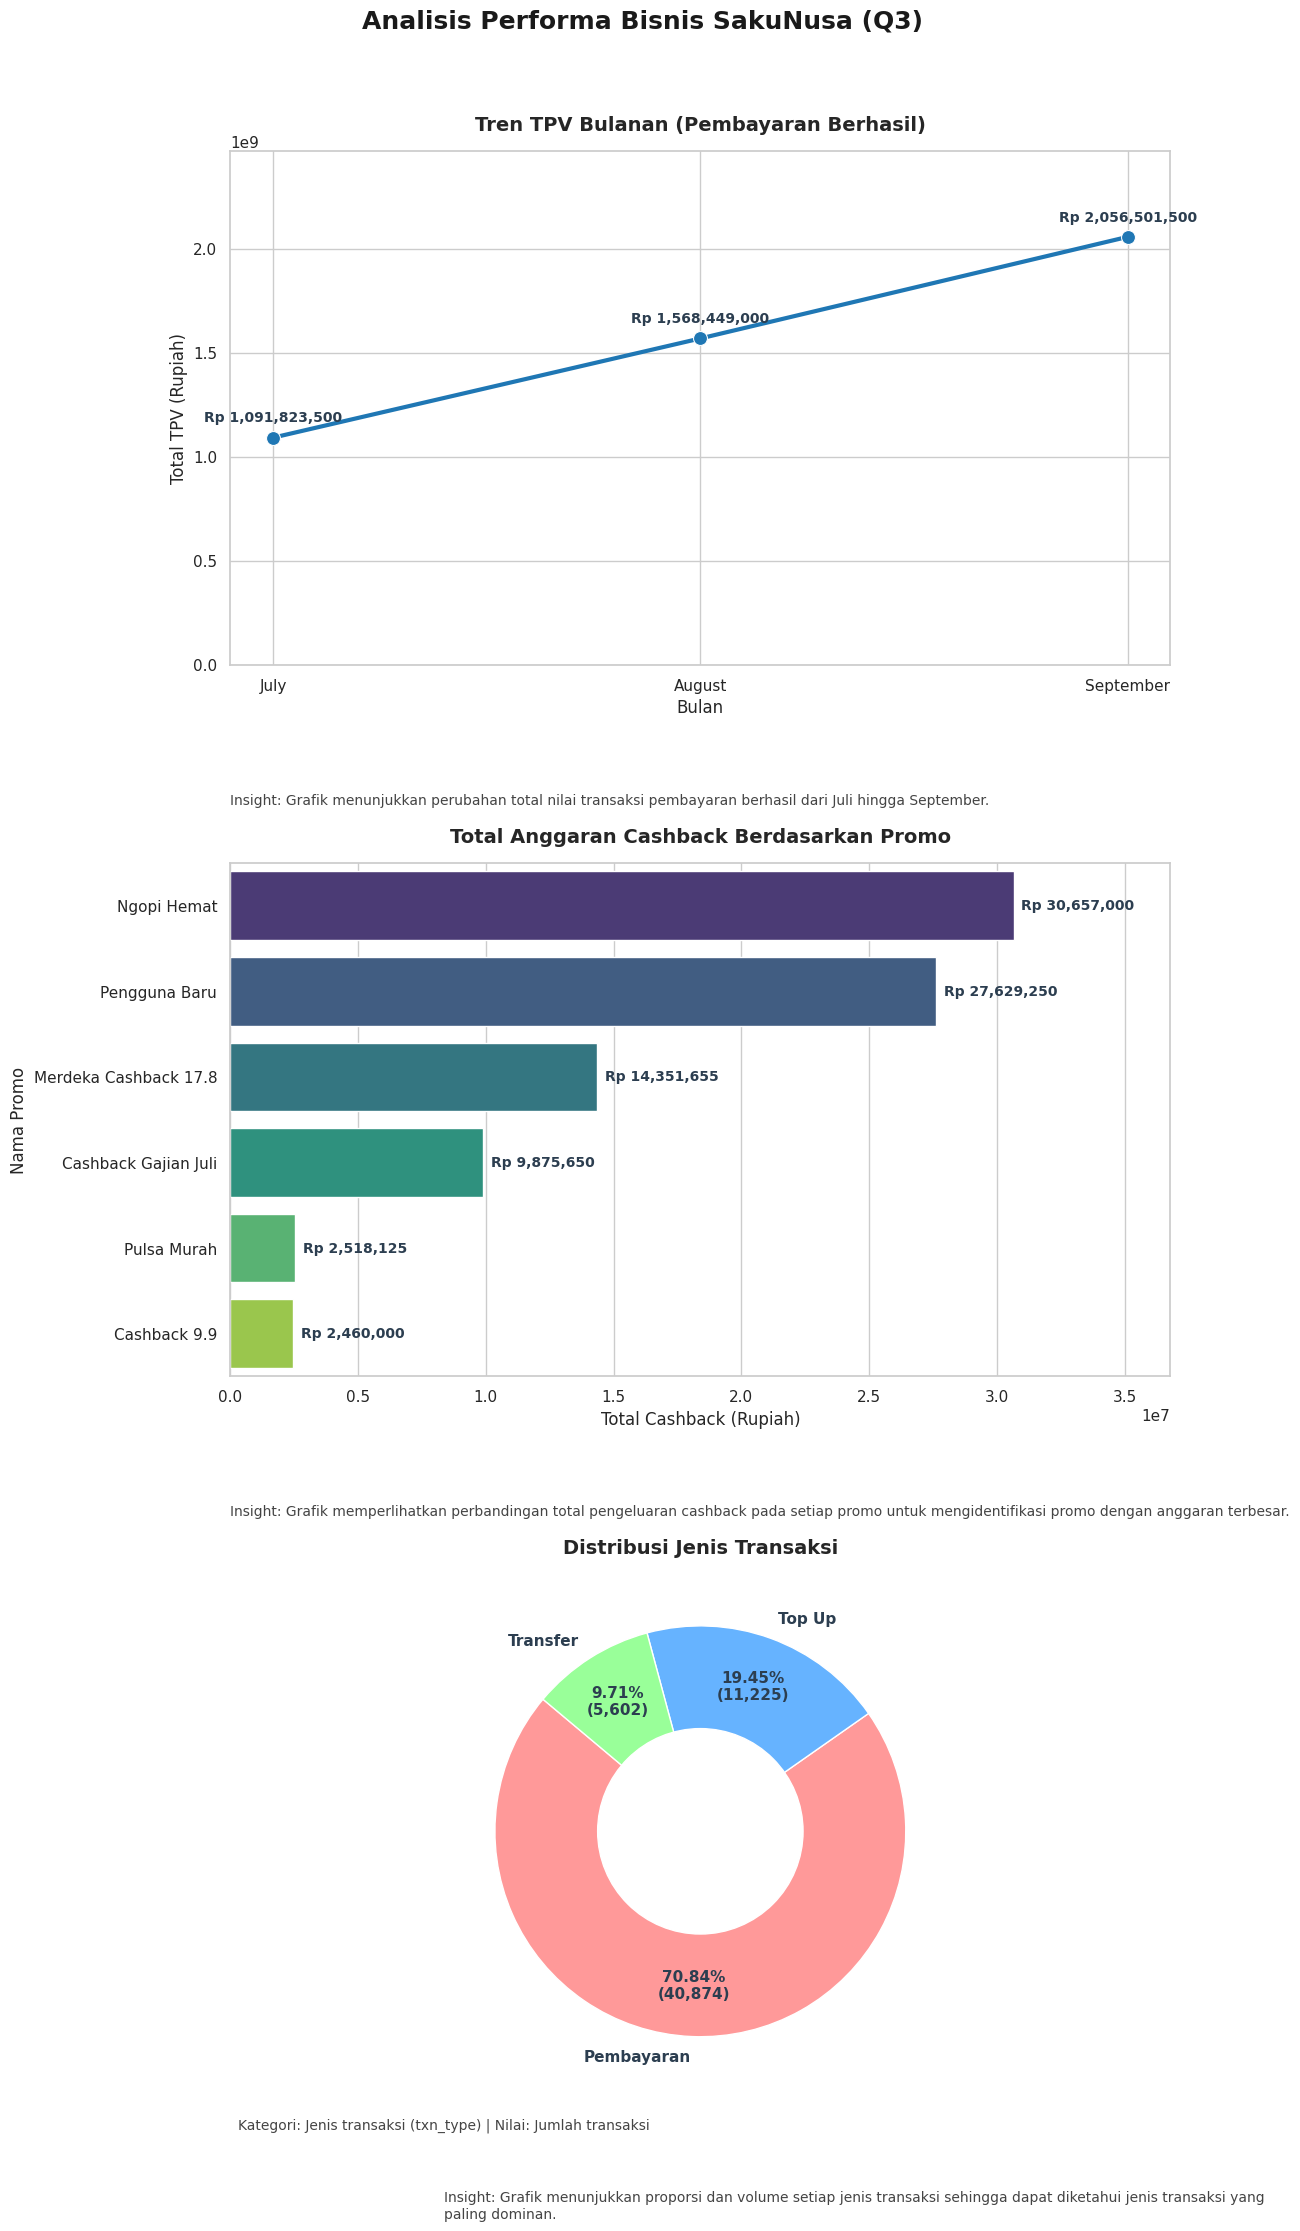

In [ ]:

# Mengatur gaya visualisasi
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(3, 1, figsize=(13, 23))

fig.suptitle(
    'Analisis Performa Bisnis SakuNusa (Q3)',
    fontsize=18,
    fontweight='bold',
    color='#1a1a1a',
    y=0.99
)

# ------------------------------------------------------------
# 1. LINE CHART: Tren Bulanan TPV
# ------------------------------------------------------------

tpv_data = df_sakunusa_clean[
    (df_sakunusa_clean['txn_type'] == 'Pembayaran') &
    (df_sakunusa_clean['status'] == 'Berhasil')
].groupby('txn_month')['amount'].sum().reindex(
    ['July', 'August', 'September']
).reset_index()

sns.lineplot(
    ax=axes[0],
    data=tpv_data,
    x='txn_month',
    y='amount',
    marker='o',
    linewidth=3,
    markersize=10,
    color='#1f77b4'
)

axes[0].set_title(
    'Tren TPV Bulanan (Pembayaran Berhasil)',
    fontsize=14,
    fontweight='bold',
    pad=15
)
axes[0].set_xlabel('Bulan', fontsize=12)
axes[0].set_ylabel('Total TPV (Rupiah)', fontsize=12)

axes[0].set_ylim(0, tpv_data['amount'].max() * 1.2)

# Data labels
for x_idx, y_val in enumerate(tpv_data['amount']):
    axes[0].text(
        x_idx,
        y_val + (tpv_data['amount'].max() * 0.03),
        f"Rp {y_val:,.0f}",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        color='#2c3e50'
    )

# Interpretasi
axes[0].text(
    0, -0.25,
    'Insight: Grafik menunjukkan perubahan total nilai transaksi '
    'pembayaran berhasil dari Juli hingga September.',
    transform=axes[0].transAxes,
    fontsize=10,
    color='#444444',
    wrap=True,
    va='top'
)


# ------------------------------------------------------------
# 2. BAR CHART: Pengeluaran Cashback per Promo
# ------------------------------------------------------------

promo_cashback = df_sakunusa_clean[
    (df_sakunusa_clean['promo_name'] != 'Tanpa Promo') &
    (df_sakunusa_clean['txn_type'] == 'Pembayaran')
].groupby('promo_name')['cashback_amount'].sum(
).sort_values(ascending=False).reset_index()

sns.barplot(
    ax=axes[1],
    data=promo_cashback,
    x='cashback_amount',
    y='promo_name',
    hue='promo_name',
    palette='viridis',
    legend=False
)

axes[1].set_title(
    'Total Anggaran Cashback Berdasarkan Promo',
    fontsize=14,
    fontweight='bold',
    pad=15
)
axes[1].set_xlabel('Total Cashback (Rupiah)', fontsize=12)
axes[1].set_ylabel('Nama Promo', fontsize=12)

axes[1].set_xlim(
    0,
    promo_cashback['cashback_amount'].max() * 1.2
)

# Data labels
for idx, row in promo_cashback.iterrows():
    axes[1].text(
        row['cashback_amount'] + (
            promo_cashback['cashback_amount'].max() * 0.01
        ),
        idx,
        f"Rp {row['cashback_amount']:,.0f}",
        va='center',
        ha='left',
        fontsize=10,
        fontweight='bold',
        color='#2c3e50'
    )

# Interpretasi
axes[1].text(
    0, -0.25,
    'Insight: Grafik memperlihatkan perbandingan total pengeluaran '
    'cashback pada setiap promo untuk mengidentifikasi promo '
    'dengan anggaran terbesar.',
    transform=axes[1].transAxes,
    fontsize=10,
    color='#444444',
    wrap=True,
    va='top'
)


# ------------------------------------------------------------
# 3. DONUT CHART: Distribusi Jenis Transaksi
# ------------------------------------------------------------

txn_distribution = df_sakunusa_clean['txn_type'].value_counts()

colors = ['#ff9999', '#66b3ff', '#99ff99']

axes[2].pie(
    txn_distribution,
    labels=txn_distribution.index,
    autopct=lambda p: (
        f'{p:.2f}%\n'
        f'({int(p * sum(txn_distribution) / 100):,})'
    ),
    startangle=140,
    colors=colors,
    textprops={
        'fontsize': 11,
        'fontweight': 'bold',
        'color': '#2c3e50'
    },
    pctdistance=0.75
)

# Membuat efek Donut Chart
centre_circle = plt.Circle(
    (0, 0),
    0.50,
    fc='white'
)
axes[2].add_artist(centre_circle)

axes[2].set_title(
    'Distribusi Jenis Transaksi',
    fontsize=14,
    fontweight='bold',
    pad=15
)

# Keterangan kategori untuk donut chart
axes[2].text(
    0, -0.08,
    'Kategori: Jenis transaksi (txn_type) | Nilai: Jumlah transaksi',
    transform=axes[2].transAxes,
    ha='center',
    fontsize=10,
    color='#444444'
)

# Interpretasi
axes[2].text(
    0, -0.20,
    'Insight: Grafik menunjukkan proporsi dan volume setiap jenis '
    'transaksi sehingga dapat diketahui jenis transaksi '
    'yang paling dominan.',
    transform=axes[2].transAxes,
    fontsize=10,
    color='#444444',
    wrap=True,
    va='top'
)


# ------------------------------------------------------------
# FINAL LAYOUT
# ------------------------------------------------------------

plt.tight_layout(rect=[0, 0.02, 1, 0.97])
plt.show()


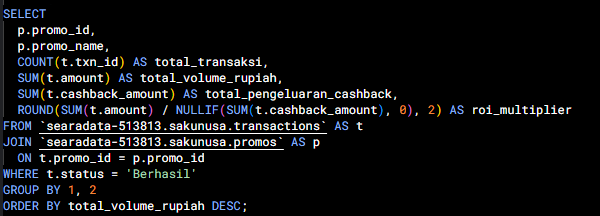

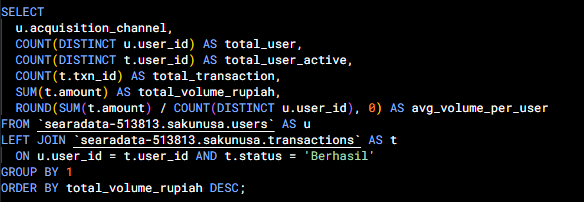

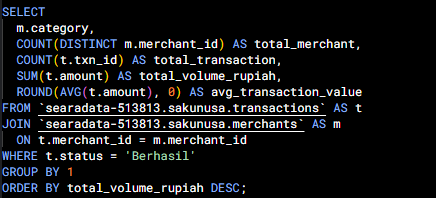